In [13]:
# Script that runs simulation at the optimal paramters for the main figures of the paper
# Outputs delay firing rates for optimal conditions

import os
import sys
import numpy as np

# Add the project root to the Python PATH
script_dir = os.getcwd()
project_root = os.path.abspath(os.path.join(script_dir, '../models/model_pet_nmda'))
sys.path.append(project_root)

from src.data import load_and_preprocess_data as get_data
from src.models import WorkingMemoryNetwork
from config.WM_params import WorkingMemoryParameters
import time
np.set_printoptions(threshold=np.inf)

random_seed = 666
outside_rng = np.random.default_rng(random_seed)

data = get_data(data_folder_path='../data/processed', parcellation='schaefer200')
area_names = data['area_names']
SLN = data['SLN']
W = data['W']
h = data['hier_vals']
normalized_nmda_rd = data['nmda_rd']

# Initial condition and parameters
N = len(area_names)
Y0 = np.zeros((N, 8))
Y0[:, 0:3] = 5 * (1 + np.tanh(outside_rng.normal(0, 2, (N, 3)))) # r values are initialized randomly between 0 and 10
WM_params = WorkingMemoryParameters()
WM_params.update(G=0.83, ALPHA=1.34, J_MAX=0.3) # Update G and alpha to optimal settings
# Generate the network
WM_network = WorkingMemoryNetwork(area_names=area_names, Y0=Y0, W=W, F=SLN, h=h,
                                  normalized_nmda_rd=normalized_nmda_rd,
                                  params=WM_params, gradient='NMDA')
# Run the simulation
t_end = 7
dt = 0.5e-3
stim_start_time = 2
stim_duration = 0.5
t_eval = np.arange(0, t_end+dt, dt) # Time points of the simulation
I_ext_strength = np.zeros((N, 3))

# Target names for which we want to assign 0.3
target_names = ['Vis_5', 'Vis_7',  'Vis_9']
# Find indexes of the target names in the list
rows = np.where(np.isin(area_names, target_names))[0]
I_ext_strength[rows, 0] = 0.3

start = time.perf_counter()
state_history, input_history = WM_network.run(t_end=t_end, dt=dt, I_ext_strengths=np.stack([I_ext_strength]),
                               ts_ext_start=np.array([stim_start_time]),
                               ts_ext_end=np.array([stim_start_time + stim_duration]))
end = time.perf_counter()
print("Elapsed (after compilation) = {}s".format((end - start)))

avg_firing_rates_A, avg_firing_rates_B = WM_network.save_avg_firing_rates_last_two_seconds(variables=['r_A', 'r_B'])
state_history_extract = WM_network.get_state_histories(['r_A'])[-1]
np.save('saved_plots/Supp_Figure_2/cue_FR_G083_alpha134.npy', state_history_extract[int(stim_start_time / dt) + 100, :, 0])
avg_firing_rates = WM_network.save_avg_firing_rates_last_two_seconds()
np.save('saved_plots/Supp_Figure_2/delay_FR_G083_alpha134.npy', avg_firing_rates)

_, pops = WM_network.check_sustained_activity_after_stim_removal()

# Need condition to check if it's A or B there, right now r_B is at index 0, it gets pops_A as pops_B.
try:
    pops_A = pops[0][1]
except:
    pops_A = []
try:
    pops_B = pops[1][1]
except:
    pops_B = []

print('Nodes where population B is persistent:', pops_B)
spont_switch, pop_switch = WM_network.check_spontaneous_switch_to_high_state(stim_start_time)
print(f'There is spontaneous switch to higher state: {spont_switch}, in populations {pop_switch}')
changes_detected, changed_populations = WM_network.check_sustained_activity_after_stim_removal()
print(changed_populations)
try:
    print('Number of persistent areas:', len(changed_populations[0][1]))
    areas_persistent = [area_names[i] for i in changed_populations[0][1]]
    print('Areas persistent:', areas_persistent)
    np.save('saved_plots/Supp_Figure_2/persistent_areas_G083_alpha134.npy', areas_persistent)
except:
    print('No persistent areas')

# Plot the results
target_area_names=['Vis_10', 'Vis_14', 'SomMot_2', 'SomMot_6', 
                   'SalVentAttn_PFCl_1', 'Default_Temp_5',
                   'Cont_PFCl_3', 'Default_PFC_7']
_ = WM_network.plot_n_areas(xlim=(-2, t_end - 2), ylim=(-5, 65),
                            target_area_names=target_area_names,
                            names_for_figures=target_area_names,
                            variables=['r_A', 'r_B'], colors=['#56c68a', '#eaa8b7'],
                            save_path='saved_plots/Supp_Figure_2/persistent_activity.svg',
                            legend=False,
                            show=False)
_ = WM_network.plot_avg_firing_rates_last_two_seconds(save_path='saved_plots/Supp_Figure_2/avg_last_2_s.svg',
                                                       color=['#56c68a', '#eaa8b7'], show=False)

Elapsed (after compilation) = 0.9408438940008637s
Nodes where population B is persistent: []
There is spontaneous switch to higher state: False, in populations []
[('r_A', [31, 38, 41, 44, 45, 46, 47, 48, 49, 50, 51, 55, 56, 57, 58, 59, 60, 63, 64, 65, 66, 67, 72, 73, 74, 75, 79, 80, 81, 82, 83, 85, 87, 88, 89, 90, 91, 92, 93, 94])]
Number of persistent areas: 40
Areas persistent: ['DorsAttn_Post_2', 'DorsAttn_Post_9', 'DorsAttn_FEF_2', 'SalVentAttn_ParOper_2', 'SalVentAttn_ParOper_3', 'SalVentAttn_FrOperIns_1', 'SalVentAttn_FrOperIns_2', 'SalVentAttn_FrOperIns_3', 'SalVentAttn_FrOperIns_4', 'SalVentAttn_PFCl_1', 'SalVentAttn_Med_1', 'Limbic_OFC_2', 'Limbic_TempPole_1', 'Limbic_TempPole_2', 'Limbic_TempPole_3', 'Limbic_TempPole_4', 'Cont_Par_1', 'Cont_Temp_1', 'Cont_OFC_1', 'Cont_PFCl_1', 'Cont_PFCl_2', 'Cont_PFCl_3', 'Cont_Cing_2', 'Default_Temp_1', 'Default_Temp_2', 'Default_Temp_3', 'Default_Par_2', 'Default_Par_3', 'Default_Par_4', 'Default_PFC_1', 'Default_PFC_2', 'Default_PFC_4',

## Combined 2x4 activity panel (Figure 1 style)

Single figure, 2/3 of the 18.4 cm page width by 5 cm, Open Sans at 7 pt.
Reuses the simulation from the first cell, so run that first.

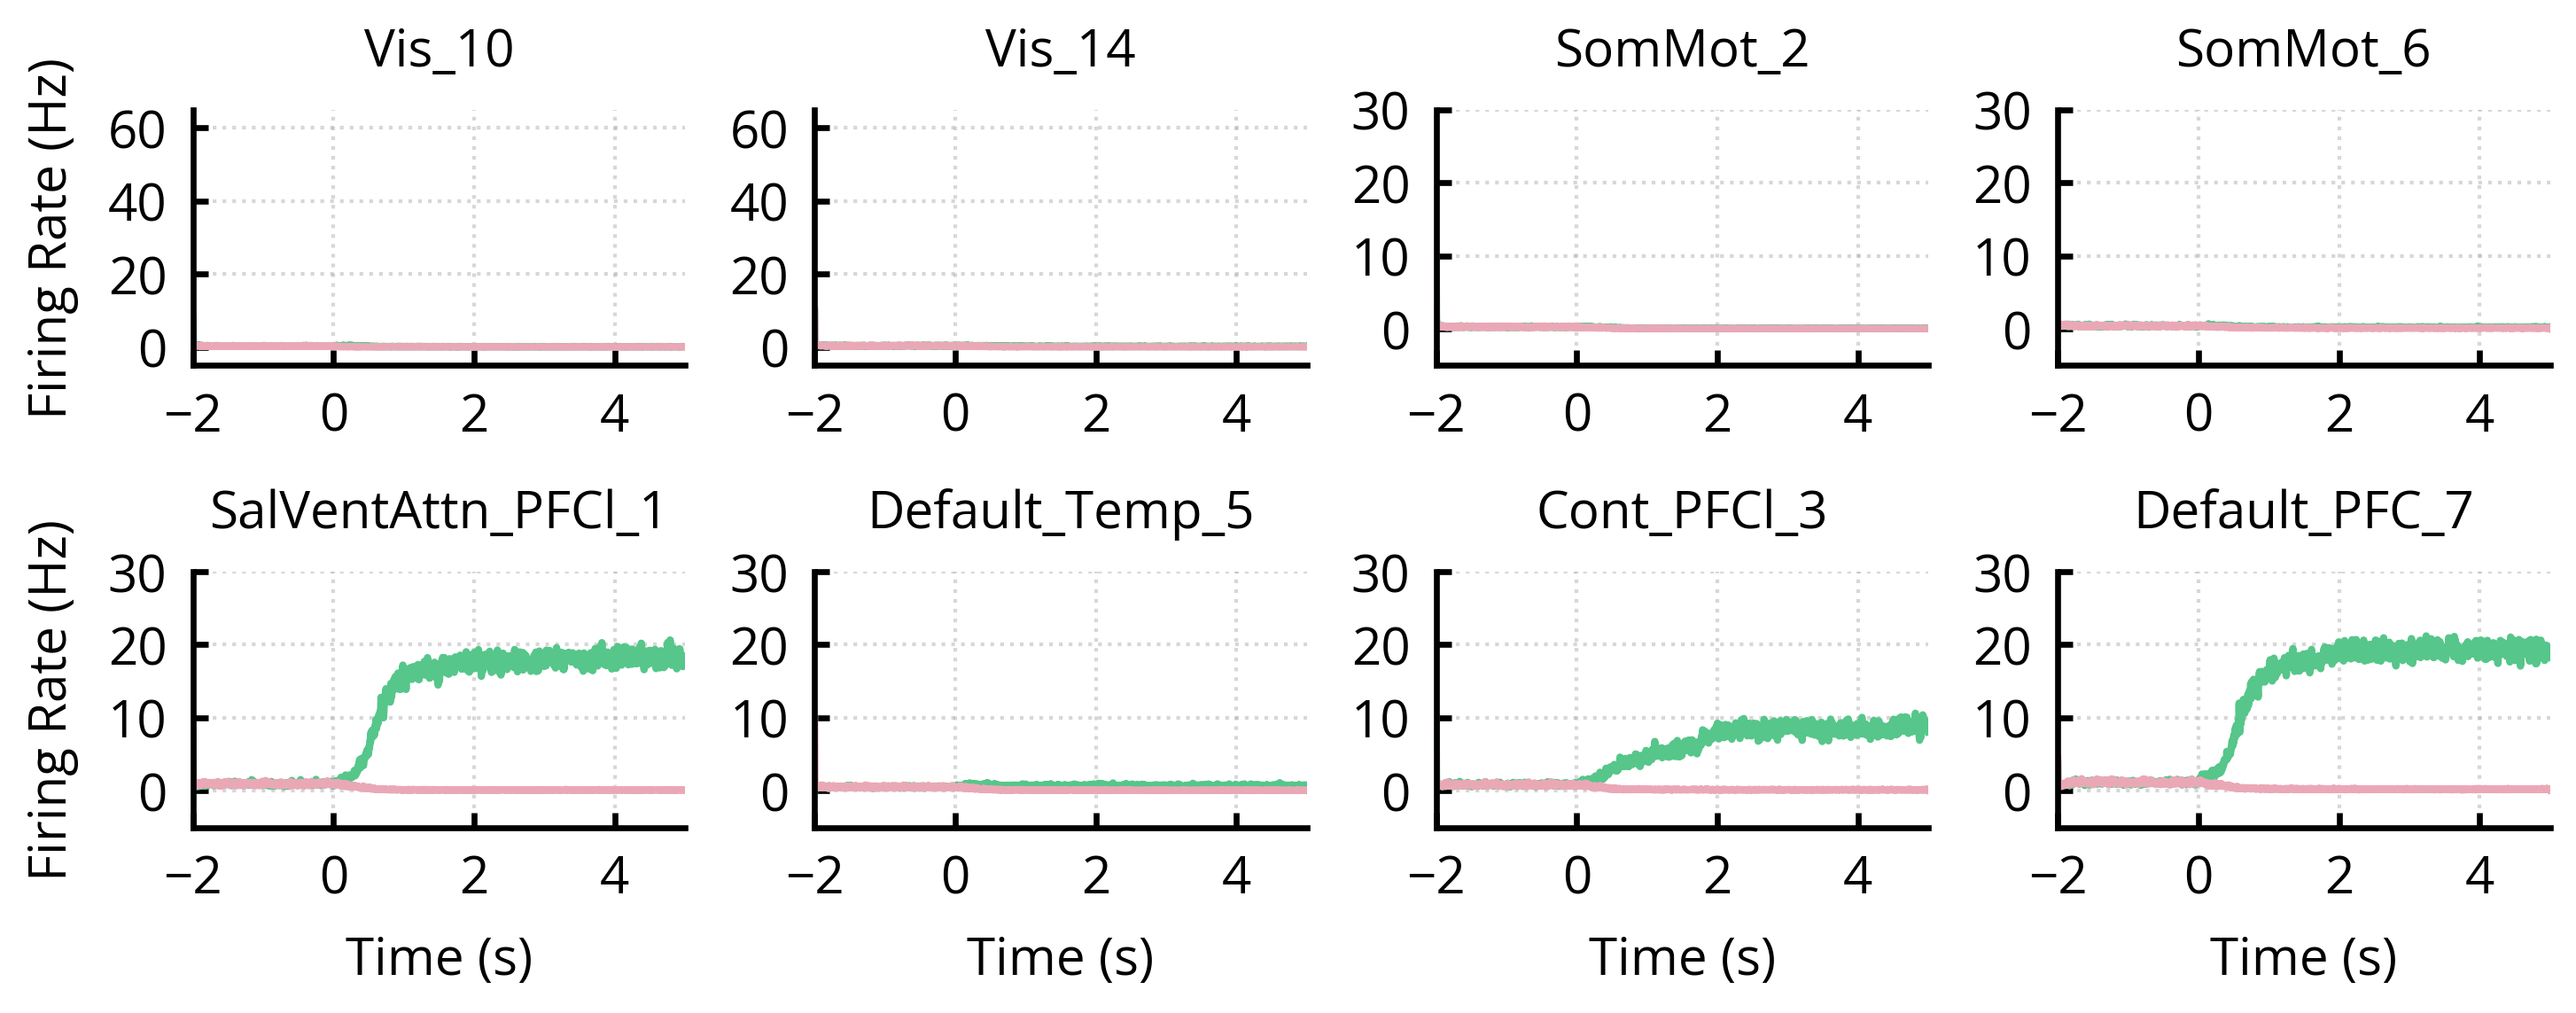

In [14]:
# Single 2x4 panel version of the plot_n_areas figure above
# 2/3 of the 18.4 cm page width by 5 cm, Open Sans at 7 pt.
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

panel_style = {
    "text.usetex": False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Open Sans"],
    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "legend.title_fontsize": 7,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 2,
    "ytick.major.size": 2,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
}

variables = ['r_A', 'r_B']
colors = ['#56c68a', '#eaa8b7']
downsample = 10

# Same data plot_n_areas uses internally
state_history = WM_network.get_state_histories(variables)[-1]  # (n_timepoints, n_areas, n_variables)
t_down = WM_network.time_histories[-1][::downsample]

# figsize is in inches, so divide the cm by 2.54
CM = 2.54
FIG_W = 2 / 3 * 18.4 / CM
FIG_H = 4.8 / CM

with mpl.rc_context(panel_style):
    # sharex: all panels have the same time axis, so only the bottom row needs tick labels
    fig, axes = plt.subplots(2, 4, figsize=(FIG_W, FIG_H),
                             constrained_layout=True, sharex=True)

    for i, (ax, area_name) in enumerate(zip(axes.flat, target_area_names)):
        area_idx = np.where(np.array(WM_network.area_names) == area_name)[0][0]
        for var_idx, var in enumerate(variables):
            data = state_history[:, area_idx, var_idx][::downsample]
            # time is shifted so that 0 is the stimulus onset, as in plot_n_areas
            ax.plot(t_down - stim_start_time, data,
                    color=colors[var_idx], linewidth=1)

        ax.set_title(target_area_names[i])
        ax.set_xlim(-2, t_end - 2)
        # same rule as plot_n_areas: the two stimulated areas get the larger y range
        ax.set_ylim(-5, 65) if i < 2 else ax.set_ylim(-5, 30)

        ax.minorticks_off()
        ax.xaxis.set_major_locator(MaxNLocator(4))
        ax.yaxis.set_major_locator(MaxNLocator(4))
        for spine in ['top', 'right']:
            ax.spines[spine].set_visible(False)
        ax.xaxis.set_ticks_position('bottom')
        ax.yaxis.set_ticks_position('left')
        ax.grid(linestyle=':', alpha=0.5)

        # axis labels only on the outer panels, they would not fit on all eight
        if i % 4 == 0:
            ax.set_ylabel('Firing Rate (Hz)')
        if i >= 4:
            ax.set_xlabel('Time (s)')

    # no bbox_inches='tight', so the file keeps the exact 12.27 x 5 cm size
    fig.savefig('saved_plots/Supp_Figure_2/persistent_activity_grid.svg')
    plt.show()

## Journal-sized version of the delay firing-rate figure, with labelled areas

The same plot `plot_avg_firing_rates_last_two_seconds` produces (areas sorted by their population A
delay rate, populations A and B drawn at the same x), redrawn at 7.5 x 5 cm with Open Sans at 7 pt,
like the panel above.

Areas can be called out by name: `HIGHLIGHT_AREAS` takes a list of area names, or `None` to pick the
`N_AUTO` lowest and `N_AUTO` highest delay-rate areas automatically. `NAMES_FIGURE` gives the name each
of those areas is printed with on the figure, one entry per `HIGHLIGHT_AREAS` entry and in the same
order (set it to `None` to print the raw area names); areas picked automatically keep their area name. Each highlighted area gets an
open circle on its population A rate and a label on a leader line. Labels sit
above their marker and are stacked when several highlighted areas are close together in rank, so they
never print on top of each other; `LABEL_OFFSETS` overrides the position per area if needed.

Reuses `WM_network` from the first cell, so run that first.

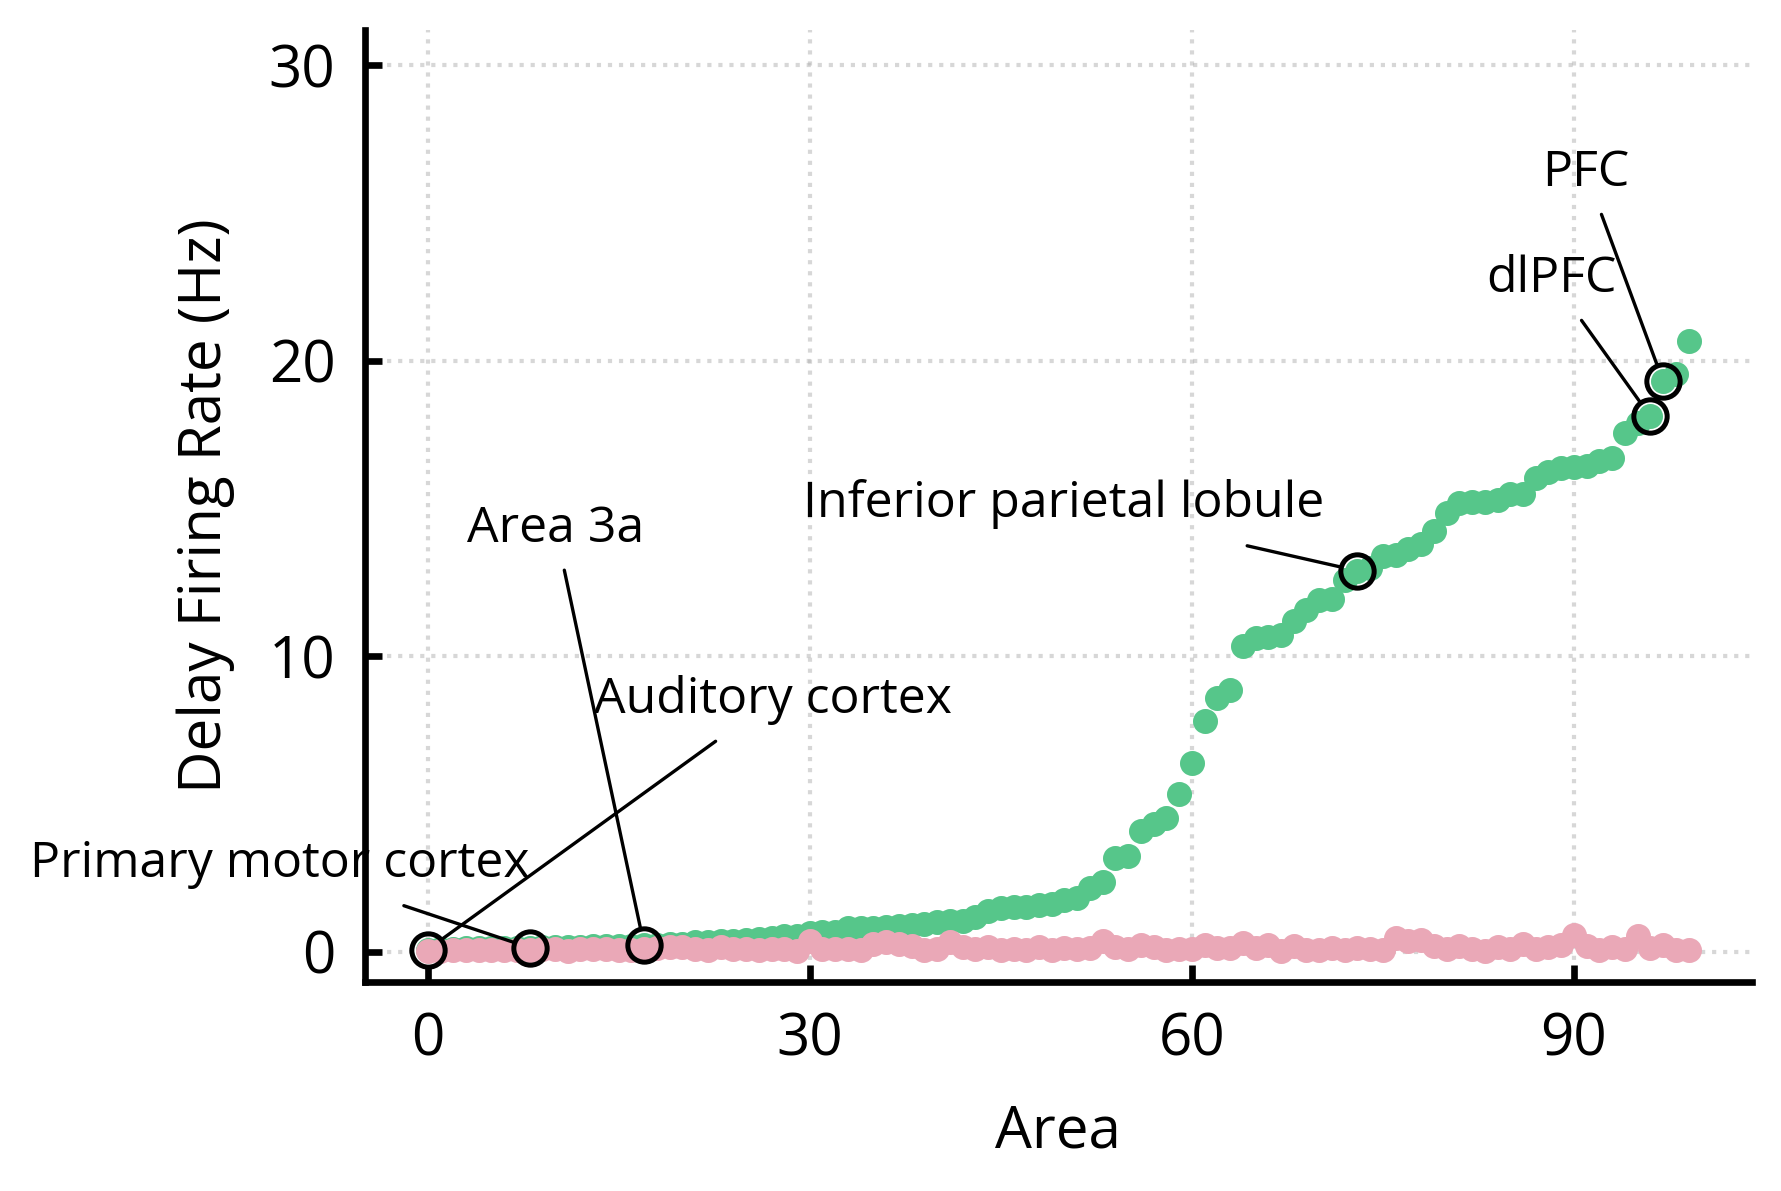

Panel is 7.5 x 5.0 cm, 100 areas
Labelled: SomMot_15 -> "Primary motor cortex" (0.1 Hz), SomMot_6 -> "Area 3a" (0.2 Hz), SomMot_2 -> "Auditory cortex" (0.1 Hz), SalVentAttn_PFCl_1 -> "dlPFC" (18.1 Hz), Default_Par_4 -> "Inferior parietal lobule" (12.9 Hz), Default_PFC_7 -> "PFC" (19.3 Hz)


In [32]:
# Journal-sized version of plot_avg_firing_rates_last_two_seconds, with labelled areas.
# 7.5 x 5 cm, Open Sans at 7 pt (panel_style is the dict defined in the cell above).
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# ---- what to label ---------------------------------------------------------------
# A list of area names, or None to take the N_AUTO lowest and N_AUTO highest delay rates.
HIGHLIGHT_AREAS = ['SomMot_15', 'SomMot_6', 'SomMot_2', 'SalVentAttn_PFCl_1', 'Default_Par_4', 'Default_PFC_7']
# The names printed on the figure, one per entry of HIGHLIGHT_AREAS and in the same order.
# Set to None to print the raw area names instead (also what happens when HIGHLIGHT_AREAS is None).
NAMES_FIGURE = ['Primary motor cortex', 'Area 3a', 'Auditory cortex', 'dlPFC', 'Inferior parietal lobule', 'PFC']
N_AUTO = 3
# Per-area override of the label position, in points relative to the marker,
# e.g. {'Default_PFC_7': (-6, -14)}. Keyed by the area name (not the figure name).
# Anything not listed here is placed automatically.
LABEL_OFFSETS = {'SomMot_15': (0, 10), 'SomMot_6': (0, 50),
                 'SomMot_2': (20, 30)}

pop_colors = ('#56c68a', '#eaa8b7')   # same colours as the plot call in the first cell

# figsize is in inches, so divide the cm by 2.54
CM = 2.54
FIG_W = 7.5 / CM
FIG_H = 5.0 / CM

# ---- same data the method computes internally ------------------------------------
t_hist = WM_network.time_histories[-1]
state_hist_fr = WM_network.get_state_histories(['r_A', 'r_B'])[-1]
delay_idx = np.where(t_hist >= t_hist[-1] - 2)[0]        # last two seconds
rate_A = np.mean(state_hist_fr[delay_idx, :, 0], axis=0)
rate_B = np.mean(state_hist_fr[delay_idx, :, 1], axis=0)

# Areas are sorted by their population A rate; rank[i] is the x position of area i
order = np.argsort(rate_A)
rank = np.empty_like(order)
rank[order] = np.arange(len(order))
all_names = np.asarray(WM_network.area_names)

if HIGHLIGHT_AREAS is None:
    # the N_AUTO quietest and the N_AUTO most active areas in the delay period
    highlight = list(all_names[order[:N_AUTO]]) + list(all_names[order[-N_AUTO:]])
else:
    highlight = list(HIGHLIGHT_AREAS)

# What each highlighted area is called on the figure. The areas picked automatically
# (HIGHLIGHT_AREAS is None) have no figure name, so they keep their area name.
if HIGHLIGHT_AREAS is not None and NAMES_FIGURE is not None:
    if len(NAMES_FIGURE) != len(HIGHLIGHT_AREAS):
        raise ValueError(f'NAMES_FIGURE has {len(NAMES_FIGURE)} entries but HIGHLIGHT_AREAS '
                         f'has {len(HIGHLIGHT_AREAS)}; they must correspond one to one.')
    figure_names = dict(zip(HIGHLIGHT_AREAS, NAMES_FIGURE))
else:
    figure_names = {}

# Labels always sit above their marker, on a leader line. Highlighted areas that are
# close together in rank would otherwise print on top of each other, so they are stacked:
# within each half of the x axis, the labels are ordered by rank and pushed up one slot at
# a time. Left-half labels run to the right of the marker, right-half ones to the left, so
# neither runs off the edge of the figure.
LABEL_DY0 = 8       # height of the first label above its marker, in points
LABEL_DSTEP = 8.5   # extra height per stacked label, in points

highlight_idx = []
for name in highlight:
    matches = np.where(all_names == name)[0]
    if matches.size == 0:
        raise ValueError(f"Area '{name}' not found in WM_network.area_names.")
    highlight_idx.append(int(matches[0]))

half = len(order) / 2
slot_counter = {True: 0, False: 0}   # one stack for the left half, one for the right
label_pos = {}
for i in sorted(highlight_idx, key=lambda i: rank[i]):
    on_left = rank[i] < half
    slot = slot_counter[on_left]
    slot_counter[on_left] += 1
    label_pos[i] = (4, LABEL_DY0 + slot * LABEL_DSTEP) if on_left \
        else (-4, LABEL_DY0 + slot * LABEL_DSTEP)

with mpl.rc_context(panel_style):
    fig, ax = plt.subplots(figsize=(FIG_W, FIG_H), constrained_layout=True)

    ax.plot(np.arange(len(order)), rate_A[order], 'o', color=pop_colors[0],
            markersize=2, label='Pop A')
    ax.plot(np.arange(len(order)), rate_B[order], 'o', color=pop_colors[1],
            markersize=2, label='Pop B')

    # headroom above the highest point so the stacked labels stay inside the axes
    ax.set_ylim(top=rate_A.max() * (1.15 + 0.12 * max(slot_counter.values())))

    for i in highlight_idx:
        name = all_names[i]
        x = rank[i]

        # open circle on the population A rate only
        ax.plot(x, rate_A[i], 'o', markerfacecolor='none', markeredgecolor='black',
                markeredgewidth=0.6, markersize=4, zorder=5)

        dx, dy = LABEL_OFFSETS.get(name, label_pos[i])
        ax.annotate(figure_names.get(name, name), (x, rate_A[i]),
                    textcoords='offset points', xytext=(dx, dy),
                    ha='left' if dx > 0 else 'right', va='center',
                    fontsize=6, color='black', zorder=6,
                    arrowprops=dict(arrowstyle='-', linewidth=0.4,
                                    color='black', shrinkA=0, shrinkB=2))

    ax.set_xlabel('Area')
    ax.set_ylabel('Delay Firing Rate (Hz)')
    ax.minorticks_off()
    ax.xaxis.set_major_locator(MaxNLocator(4))
    ax.yaxis.set_major_locator(MaxNLocator(4))
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    ax.xaxis.set_ticks_position('bottom')
    ax.yaxis.set_ticks_position('left')
    ax.grid(linestyle=':', alpha=0.5)

    # no bbox_inches='tight', so the files keep the exact 7.5 x 5 cm size
    fig.savefig('saved_plots/Supp_Figure_2/avg_last_2_s_journal.svg')
    fig.savefig('saved_plots/Supp_Figure_2/avg_last_2_s_journal.pdf')
    plt.show()

print(f'Panel is {FIG_W * CM:.1f} x {FIG_H * CM:.1f} cm, {len(order)} areas')
print('Labelled:', ', '.join(
    f'{n} -> "{figure_names.get(n, n)}" ({rate_A[np.where(all_names == n)[0][0]]:.1f} Hz)'
    for n in highlight))